In [6]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from astropy.io import fits
from astropy.table import Table
from glob import glob
plt.ion()
import os

In [32]:
t = Table.read('data/SMIDGE_BEAST-final_w_obscat_avsnr6_cuts_stats.fits')
print(len(t))
ra = t["RA"]
dec = t["DEC"]
av = t["Av_p50_1"]
temp = t["logT_p50_1"]
print(np.median(av))
t_smc_av = t[av>0.18]
t_smc_high_ext = t[av > np.median(av)]
t_hot_stars = t[temp >= 4]
print("SMC-only ext", len(t_smc_high_ext))
temp_hight_ext = t_smc_high_ext["logT_p50_1"]


44065
0.7920817059952906
SMC-only ext 22032


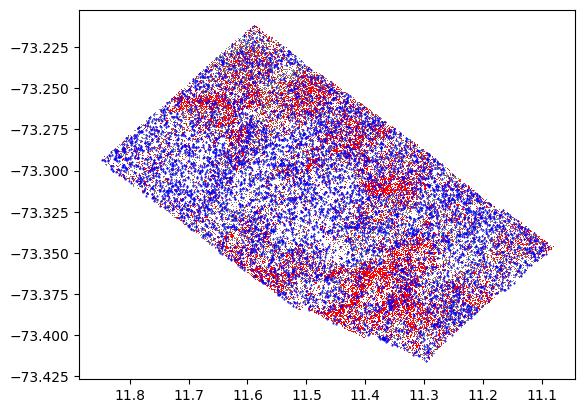

In [23]:
plt.figure()
plt.plot(ra, dec, ',', c='grey', ls='')
plt.plot(t_smc_high_ext["RA"], t_smc_high_ext["DEC"], ',r', ls='')
plt.plot(t_hot_stars["RA"], t_hot_stars["DEC"], '.b', ms=1, ls='')
ax=plt.gca()
ax.invert_xaxis()

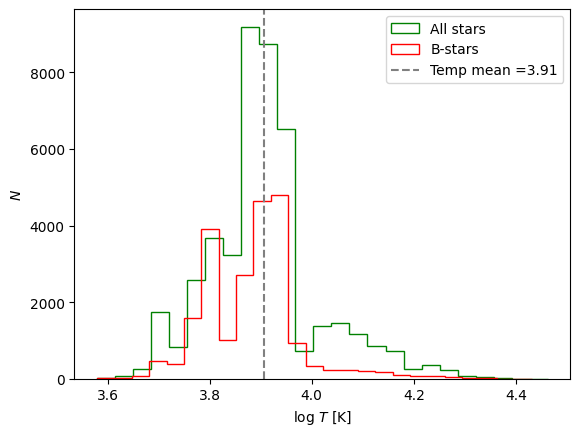

In [37]:
plt.figure()
plt.hist(temp, histtype='step', bins=25, color='g', label = 'All stars')
plt.hist(temp_hight_ext, histtype='step', bins=25, color='r', label = 'B-stars')
plt.ylabel('$N$')
plt.xlabel('log $T$ [K]')
tm = np.mean(temp)
plt.axvline(tm, 0, max(temp), ls='--', color='grey',
            label='Temp mean ={}'.format(np.around(tm, decimals=2)))
plt.legend()
